# Propensity Modeling & Segmentation
- Justin Wall, Data Scientist, Antler Industrial Supply

## Data Import

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_PATH = "../data/antler_industrial_accounts.csv"  # adjust to your path
df = pd.read_csv(DATA_PATH)

print(df.shape)
print("duplicate ids:", df.account_id.duplicated().sum())
print("nulls:", df.isna().sum().sum())
print("Number of Regions:", df.region.nunique())
print("Number of Verticals:", df.industry_vertical.nunique())
print("Distinct number of assigned reps:", df.assigned_rep_id.nunique())
print("Number of employee bands:", df.employee_band.nunique())
print("Number of loyalty tiers:", df.loyalty_tier.nunique())
df.describe().T[["min", "50%", "mean", "max"]].round(2)

(12000, 20)
duplicate ids: 0
nulls: 0
Number of Regions: 5
Number of Verticals: 6
Distinct number of assigned reps: 38
Number of employee bands: 4
Number of loyalty tiers: 4


,min,50%,mean,max
account_age_months,1.0,43.50,49.76,240.00
orders_12m,0.0,4.00,7.69,257.00
orders_last_90d,0.0,1.00,1.99,49.00
revenue_12m,0.0,5142.36,11497.18,435454.54
avg_order_value,0.0,1126.85,1458.13,28950.01
days_since_last_order,0.0,55.00,117.29,730.00
lifetime_orders,1.0,14.00,33.19,1691.00
consumables_revenue_share,0.0,0.53,0.53,1.00
email_open_rate_90d,0.0,0.40,0.41,0.99
portal_logins_90d,0.0,3.00,4.09,49.00


***
### **Notes**:
- 12,000 observations
- 0 duplicates
- 0 nulls
- 2 targets
- 12 historical features
- 5 regions
- 6 industry verticals
- 38 distinct assigned reps
- 4 company sizes
- 4 loyalty tiers
***

In [2]:
df.head()

,account_id,industry_vertical,region,assigned_rep_id,employee_band,loyalty_tier,account_age_months,orders_12m,orders_last_90d,revenue_12m,avg_order_value,days_since_last_order,lifetime_orders,consumables_revenue_share,email_open_rate_90d,portal_logins_90d,quote_requests_90d,rep_contacts_90d,ordered_next_30d,next_30d_revenue
0,ANT-10001,General Manufacturing,South Central,REP-31,251+,Platinum,99,10,0,38741.23,3874.12,264,308,0.548,0.579,16,2,8,0,0.00
1,ANT-10002,Machining & Auto Parts,Southeast,REP-18,1-10,Bronze,27,0,0,0.00,0.00,665,1,0.243,0.379,2,1,1,0,0.00
2,ANT-10003,Machining & Auto Parts,Northeast,REP-15,251+,Platinum,36,6,1,24980.00,4163.33,76,23,0.299,0.563,11,1,6,1,5922.33
3,ANT-10004,Plastics & Packaging,Southeast,REP-25,1-10,Bronze,4,3,0,1881.08,627.03,103,3,0.853,0.228,2,0,2,0,0.00
4,ANT-10005,Metal Fabrication,South Central,REP-27,51-250,Silver,83,7,0,5251.36,750.19,201,41,0.803,0.449,4,0,4,1,2022.44


## Business Alignment

In [3]:
# 2a. Internal consistency: each should print True
checks = {
    "orders_90d <= orders_12m": (df.orders_last_90d <= df.orders_12m).all(),
    "orders_12m <= lifetime_orders": (df.orders_12m <= df.lifetime_orders).all(),
    "revenue == 0 iff orders == 0": ((df.revenue_12m == 0) == (df.orders_12m == 0)).all(),
    "AOV ~= revenue / orders": np.allclose(
        df.avg_order_value,
        (df.revenue_12m / df.orders_12m.replace(0, np.nan)).fillna(0),
        atol=0.02,
    ),
    "next_30d_revenue > 0 iff ordered": ((df.next_30d_revenue > 0) == (df.ordered_next_30d == 1)).all(),
    "no-order accts have recency > 365": (df.loc[df.orders_12m == 0, "days_since_last_order"] > 365).all(),
}
pd.Series(checks)

orders_90d <= orders_12m             True
orders_12m <= lifetime_orders        True
revenue == 0 iff orders == 0         True
AOV ~= revenue / orders              True
next_30d_revenue > 0 iff ordered     True
no-order accts have recency > 365    True
dtype: bool

This is less of business alignment and more of EDA

In [4]:
# 2b. Scale vs. the email: 12K accounts, 38 reps, 25-30 touches/rep/week
reps = df.groupby("assigned_rep_id").size()
print("accounts:", len(df), "| reps:", len(reps), "| regions:", df.region.nunique())
print("accounts per rep (min/median/max):", reps.min(), reps.median(), reps.max())

cap_lo, cap_hi = 38 * 25, 38 * 30
print(f"weekly capacity: {cap_lo}-{cap_hi} touches = {cap_lo/len(df):.1%}-{cap_hi/len(df):.1%} of base")
print(f"base 30d purchase rate: {df.ordered_next_30d.mean():.1%}")

# Email says ~1/3 of accounts have < 3 orders
print("orders_12m < 3:", f"{(df.orders_12m < 3).mean():.1%}")
print("zero orders in 12m:", f"{(df.orders_12m == 0).mean():.1%}")

accounts: 12000 | reps: 38 | regions: 5
accounts per rep (min/median/max): 224 319.0 378
weekly capacity: 950-1140 touches = 7.9%-9.5% of base
base 30d purchase rate: 36.7%
orders_12m < 3: 35.4%
zero orders in 12m: 8.0%


8% of our accounts are lapsed.

In [5]:
# 2c. Do tiers, verticals, regions, and size behave the way sales would expect?
tier_order = ["Bronze", "Silver", "Gold", "Platinum"]
tiers = df.groupby("loyalty_tier").agg(
    n=("account_id", "size"),
    purchase_rate=("ordered_next_30d", "mean"),
    median_rev=("revenue_12m", "median"),
    median_orders=("orders_12m", "median"),
).loc[tier_order]
tiers["share"] = tiers.n / len(df)
display(tiers.round(3))

for col in ["industry_vertical", "region", "employee_band"]:
    display(
        df.groupby(col)
        .agg(n=("account_id", "size"), purchase_rate=("ordered_next_30d", "mean"), median_orders=("orders_12m", "median"))
        .round(3)
    )

,n,purchase_rate,median_rev,median_orders,share
loyalty_tier,,,,,
Bronze,5400,0.204,1679.375,2.0,0.45
Silver,3600,0.387,7076.730,5.0,0.30
Gold,2160,0.579,17348.265,10.0,0.18
Platinum,840,0.775,46193.035,21.0,0.07


,n,purchase_rate,median_orders
industry_vertical,,,
Construction & Contracting,1636,0.257,2.0
Food & Beverage Processing,1684,0.526,8.0
General Manufacturing,1908,0.327,3.0
Machining & Auto Parts,2392,0.396,5.0
Metal Fabrication,2672,0.317,4.0
Plastics & Packaging,1708,0.395,5.0


,n,purchase_rate,median_orders
region,,,
Great Lakes,3541,0.378,4.0
Northeast,2251,0.326,3.0
South Central,1886,0.423,5.0
Southeast,2528,0.389,5.0
West,1794,0.304,3.0


,n,purchase_rate,median_orders
employee_band,,,
1-10,4144,0.246,2.0
11-50,4197,0.350,4.0
251+,968,0.632,11.0
51-250,2691,0.483,6.0


I like this one, splitting out orders & purchase rate by categories to see if it makes sense.

1. Loyalty tier makes sense, more valuable but fewer accounts in the top tiers

In [6]:
# 2d. Recency: does "days since last order" behave the way the old rule assumes?
bins = [-1, 30, 60, 90, 180, 365, 730]
display(
    df.groupby(pd.cut(df.days_since_last_order, bins), observed=True)
    .agg(n=("account_id", "size"), purchase_rate=("ordered_next_30d", "mean"))
    .round(3)
)

# 2e. Consumables vs. capital: Terrence says these behave differently
display(
    df.groupby(pd.qcut(df.consumables_revenue_share, 4), observed=True)
    .agg(median_orders=("orders_12m", "median"),
         median_aov=("avg_order_value", "median"),
         purchase_rate=("ordered_next_30d", "mean"))
    .round(3)
)

,n,purchase_rate
days_since_last_order,,
"(-1, 30]",4333,0.569
"(30, 60]",2021,0.401
"(60, 90]",1193,0.325
"(90, 180]",1922,0.234
"(180, 365]",1573,0.133
"(365, 730]",958,0.077


,median_orders,median_aov,purchase_rate
consumables_revenue_share,,,
"(-0.001, 0.344]",2.0,1872.570,0.209
"(0.344, 0.533]",3.0,1367.740,0.317
"(0.533, 0.718]",5.0,1042.100,0.399
"(0.718, 1.0]",8.0,737.725,0.542


1. Recency is related to purchase rate, and you can see a bunch of accounts 90 to 365 days old that are due for a reach-out
2. Larger consumables revenue share are related to more orders, less order value, and higher purchase rate

In [7]:
# 2f. Engagement signals vs. outcome (quartiles, low to high)
for col in ["quote_requests_90d", "portal_logins_90d", "rep_contacts_90d", "email_open_rate_90d"]:
    q = pd.qcut(df[col].rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
    print(col, df.groupby(q, observed=True).ordered_next_30d.mean().round(3).to_dict())

quote_requests_90d {'Q1 low': 0.343, 'Q2': 0.344, 'Q3': 0.367, 'Q4 high': 0.413}
portal_logins_90d {'Q1 low': 0.212, 'Q2': 0.285, 'Q3': 0.381, 'Q4 high': 0.588}
rep_contacts_90d {'Q1 low': 0.24, 'Q2': 0.289, 'Q3': 0.366, 'Q4 high': 0.571}
email_open_rate_90d {'Q1 low': 0.338, 'Q2': 0.361, 'Q3': 0.378, 'Q4 high': 0.389}


1. All 4 of these features are positively related to 30 day orders, a few of these are levers we can pull

## EDA

In [8]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

y = df.ordered_next_30d

# 3a. Target balance
print(y.value_counts(normalize=True).round(3).to_dict())

{0: 0.633, 1: 0.367}


- 63.3% no orders in next 30 days
- 36.7% ordered in next 30 days

Binary Classification Model - skipping resampling via downsampling, SMOTE, or class weights because we care about calibration

In [9]:
# 3b. Skew and outliers: does log1p fix the long tails?
num_cols = [
    "account_age_months", "orders_12m", "orders_last_90d", "revenue_12m", "avg_order_value",
    "days_since_last_order", "lifetime_orders", "consumables_revenue_share", "email_open_rate_90d",
    "portal_logins_90d", "quote_requests_90d", "rep_contacts_90d",
]
pd.DataFrame({
    "skew_raw": df[num_cols].skew(),
    "skew_log1p": np.log1p(df[num_cols]).skew(),
    "p99": df[num_cols].quantile(0.99),
    "max": df[num_cols].max(),
}).round(2)

,skew_raw,skew_log1p,p99,max
account_age_months,1.12,-0.99,165.00,240.00
orders_12m,5.43,0.30,56.00,257.00
orders_last_90d,4.48,0.72,15.00,49.00
revenue_12m,6.03,-2.04,99174.05,435454.54
avg_order_value,3.06,-2.52,6296.81,28950.01
days_since_last_order,2.05,-0.42,686.00,730.00
lifetime_orders,6.74,0.25,287.01,1691.00
consumables_revenue_share,-0.06,-0.35,1.00,1.00
email_open_rate_90d,0.21,-0.07,0.82,0.99
portal_logins_90d,2.32,-0.07,19.00,49.00


Lots of skewed features - we can log them to fix it up.

In [10]:
# 3c. Collinearity (Spearman handles the skew)
corr = df[num_cols].corr(method="spearman").abs()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
pairs[pairs > 0.7].round(2)

orders_last_90d  days_since_last_order    0.87
orders_12m       revenue_12m              0.86
                 lifetime_orders          0.77
                 orders_last_90d          0.75
dtype: float64

Heavy correlation between features here. Fine for trees, ok for regularization as well. For Bayesian, use tight priors & watch sampler.

In [11]:
# 3d. Hierarchy: is it clean, and how thin are the cells partial pooling would help?
print("reps in >1 region:", (df.groupby("assigned_rep_id").region.nunique() > 1).sum())
cell = df.groupby(["assigned_rep_id", "industry_vertical"]).size()
print("rep x vertical cell sizes:", cell.describe().round(0).to_dict())
print("thin accounts per rep:", df[df.orders_12m < 3].groupby("assigned_rep_id").size().agg(["min", "median", "max"]).to_dict())

reps in >1 region: 0
rep x vertical cell sizes: {'count': 228.0, 'mean': 53.0, 'std': 14.0, 'min': 24.0, '25%': 43.0, '50%': 50.0, '75%': 60.0, 'max': 94.0}
thin accounts per rep: {'min': 63.0, 'median': 116.5, 'max': 150.0}


Each rep is in 1 region, ignoring the rest of this because it's just EDA overkill

In [12]:
# 3e. Row-wise features (no leakage risk, so safe before the split)
exposure_days = np.minimum(df.account_age_months * 30.4, 365)       # days the account has existed, capped at 1 year
expected_gap = exposure_days / df.orders_12m.clip(lower=1)           # typical days between this account's orders
df["overdue_ratio"] = (df.days_since_last_order / expected_gap).clip(upper=20)  # >1 means later than usual
df["recent_share"] = df.orders_last_90d / df.orders_12m.clip(lower=1)           # share of 12m orders in last 90d
df["thin_flag"] = (df.orders_12m < 3).astype(int)
df["no_orders_12m"] = (df.orders_12m == 0).astype(int)

# 3f. Univariate AUC (0.5 = useless). Sign tells you direction
feats = num_cols + ["overdue_ratio", "recent_share"]
auc = pd.Series({c: roc_auc_score(y, df[c]) for c in feats})
pd.DataFrame({"auc": auc.round(3), "higher_means_more_likely": auc > 0.5}).sort_values("auc", key=lambda s: (s - 0.5).abs(), ascending=False)

,auc,higher_means_more_likely
orders_12m,0.781,True
orders_last_90d,0.750,True
revenue_12m,0.745,True
days_since_last_order,0.269,False
lifetime_orders,0.724,True
portal_logins_90d,0.679,True
rep_contacts_90d,0.655,True
consumables_revenue_share,0.654,True
recent_share,0.613,True
overdue_ratio,0.453,False


Feature engineering here
- exposure days = days the account has existed (max = 365)
- expected gap = days between accounts orders in past 12 months
- overdue ratio = day since last order / days between orders ~ are they due for an order? Could be an inverted-U (peak when slightly overdue, then churn).
- recent share = share of last years orders that were in the past 90 days
- thin flag = fewer than 3 orders, per Terrence on our email chain
- no orders past 12 m = lapsed essentially

Base Model
- Orders past 12m, ordrs past 90 days, revenue past 12m, days since last order, lifeitme orders are the best 5 features
- account age, email open rate, quote requests are the worst features


each day has the same order probability no matter how long it's been since the last order.

In [13]:
bins = [0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 2, 3, 20]
df["overdue_bin"] = pd.cut(df.overdue_ratio, bins, include_lowest=True)
df["freq_band"] = pd.cut(df.orders_12m, [-1, 2, 5, 12, 1000], labels=["0-2", "3-5", "6-12", "13+"])

display(df.groupby("overdue_bin", observed=True).agg(n=("account_id", "size"), rate=("ordered_next_30d", "mean")).round(3))
display(df.pivot_table(index="overdue_bin", columns="freq_band", values="ordered_next_30d", aggfunc="mean", observed=True).round(3))

,n,rate
overdue_bin,,
"(-0.001, 0.25]",2165,0.441
"(0.25, 0.5]",1798,0.408
"(0.5, 0.75]",1600,0.393
"(0.75, 1.0]",1997,0.287
"(1.0, 1.25]",1128,0.333
"(1.25, 1.5]",896,0.324
"(1.5, 2.0]",1446,0.301
"(2.0, 3.0]",661,0.437
"(3.0, 20.0]",309,0.388


freq_band,0-2,3-5,6-12,13+
overdue_bin,,,,
"(-0.001, 0.25]",0.188,0.299,0.522,0.804
"(0.25, 0.5]",0.160,0.316,0.499,0.814
"(0.5, 0.75]",0.159,0.337,0.505,0.803
"(0.75, 1.0]",0.146,0.273,0.457,0.754
"(1.0, 1.25]",0.130,0.258,0.506,0.831
"(1.25, 1.5]",0.106,0.304,0.455,0.843
"(1.5, 2.0]",0.112,0.253,0.486,0.813
"(2.0, 3.0]",NaN,0.225,0.424,0.797
"(3.0, 20.0]",NaN,0.150,0.322,0.540


Overdue vs purchase rate and frequency

In [14]:
# 3g. Split once (stratified on outcome x thin flag). Test set stays untouched until section 5
df["strata"] = df.ordered_next_30d.astype(str) + "_" + df.thin_flag.astype(str)
train, test = train_test_split(df, test_size=0.2, stratify=df.strata, random_state=42)
train = train.drop(columns="strata").reset_index(drop=True)
test = test.drop(columns="strata").reset_index(drop=True)

# # AOV for accounts with no orders: fill with the vertical x size median, fit on TRAIN only
# peer_keys = ["industry_vertical", "employee_band"]
# peer = (train[train.orders_12m > 0].groupby(peer_keys, as_index=False).avg_order_value.median()
#         .rename(columns={"avg_order_value": "aov_peer_median"}))
# train = train.merge(peer, on=peer_keys, how="left")
# test = test.merge(peer, on=peer_keys, how="left")
# for d in (train, test):
#     d["aov_filled"] = np.where(d.orders_12m > 0, d.avg_order_value, d.aov_peer_median)

print(train.shape, test.shape, train.ordered_next_30d.mean().round(3), test.ordered_next_30d.mean().round(3))

(9600, 26) (2400, 26) 0.367 0.367


1. Stratified sampling 80/20 on target & one thin account data (both binary)
2. hm...not sure how I feel about this...I"m ditching AOV Filled, no good.

In [15]:
# 3h. Feature lists for section 4
cat_features = ["industry_vertical", "region", "assigned_rep_id", "employee_band", "loyalty_tier"]
num_features = [c for c in num_cols if c != "avg_order_value"] + [
    "aov_filled", "overdue_ratio", "recent_share", "thin_flag", "no_orders_12m",
]
log_features = [  # log1p + standardize these for LR and Bayes. Trees can skip it
    "orders_12m", "orders_last_90d", "revenue_12m", "aov_filled", "days_since_last_order",
    "lifetime_orders", "portal_logins_90d", "quote_requests_90d", "rep_contacts_90d",
]
TARGET, VALUE_COL = "ordered_next_30d", "next_30d_revenue"  # value col is for the EV backtest only, never a feature

- preparing features for modeling & segmentation

## Segmentation

### RFM Scores
cutoffs from train, applied to test

In [16]:
def pct_rank(ref, x):
    """Share of train accounts below x (ties get the mid-rank)."""
    s = np.sort(ref.to_numpy())
    x = np.asarray(x)
    return (np.searchsorted(s, x, side="left") + np.searchsorted(s, x, side="right")) / 2 / len(s)

def add_rfm(d, ref):
    d = d.copy()
    d["R"] = np.clip(np.ceil(5 * (1 - pct_rank(ref.days_since_last_order, d.days_since_last_order))), 1, 5).astype(int)
    d["F"] = np.clip(np.ceil(5 * pct_rank(ref.orders_12m, d.orders_12m)), 1, 5).astype(int)
    d["M"] = np.clip(np.ceil(5 * pct_rank(ref.revenue_12m, d.revenue_12m)), 1, 5).astype(int)
    return d

train, test = add_rfm(train, train), add_rfm(test, train)
train[["R", "F", "M"]].apply(lambda s: s.value_counts(normalize=True).sort_index().round(2))  # ties make this uneven, that's OK


,R,F,M
1,0.20,0.23,0.2
2,0.20,0.13,0.2
3,0.20,0.24,0.2
4,0.20,0.20,0.2
5,0.21,0.21,0.2


In [17]:
pd.concat({
    "R: days since last order": train.groupby("R").days_since_last_order.agg(["min", "median", "mean", "max"]),
    "F: orders in 12m":         train.groupby("F").orders_12m.agg(["min", "median", "mean", "max"]),
    "M: revenue in 12m":        train.groupby("M").revenue_12m.agg(["min", "median", "mean", "max"]),
}, axis=1).round(1)

R: days since last order                    F: orders in 12m                   M: revenue in 12m                            
                       min median   mean  max              min median  mean  max               min   median     mean       max
1                      191  322.0  374.6  730                0    1.0   0.7    1               0.0    486.1    504.5    1385.8
2                       84  123.0  128.1  190                2    2.0   2.0    2            1386.0   2398.0   2422.3    3558.7
3                       37   56.0   57.1   83                3    4.0   3.9    5            3558.9   5108.8   5198.1    7170.4
4                       14   23.0   23.8   36                6    7.0   7.6   10            7176.9  10139.3  10538.1   15437.5
5                        0    5.0    5.8   13               11   17.0  22.8  257           15464.6  27368.8  38655.9  435454.5

- these 5 groups are our RFM segments and will be used in our segment creation.

### Business Rules
first match wins

In [18]:
def assign_segment(d):
    conds = [
        d.orders_12m == 0,                               # Lapsed
        d.account_age_months < 12,                       # New Account
        d.overdue_ratio > 3,                             # At Risk
        (d.R >= 4) & (d.F >= 4) & (d.M >= 4),            # Champion
        d.F >= 4,                                        # Steady Reorderer
        d.M >= 4,                                        # Project Buyer
        # d.R >= 4,                                        # Warm Account
    ]
    names = ["Lapsed", "New Account", "At Risk", "Champion", "Steady Reorderer", "Project Buyer"]  # "Warm Account" removed
    return np.select(conds, names, default="Low-Touch")

train["segment"], test["segment"] = assign_segment(train), assign_segment(test)

(train.groupby("segment").agg(
    n=("account_id", "size"),
    purchase_rate=("ordered_next_30d", "mean"),
    orders_12m=("orders_12m", "median"),
    revenue_12m=("revenue_12m", "median"),
    days_since_last=("days_since_last_order", "median"),
    overdue_ratio=("overdue_ratio", "median"),
    quotes=("quote_requests_90d", "mean"),
    rep_contacts=("rep_contacts_90d", "mean"),
).assign(share=lambda t: t.n / t.n.sum()).round(2).sort_values("purchase_rate", ascending=False))

,n,purchase_rate,orders_12m,revenue_12m,days_since_last,overdue_ratio,quotes,rep_contacts,share
segment,,,,,,,,,
Champion,1925,0.70,15.0,21027.44,11.0,0.44,0.69,3.63,0.20
Steady Reorderer,1335,0.48,8.0,7038.11,48.0,1.15,0.62,2.26,0.14
New Account,1703,0.38,3.0,3519.03,48.0,0.95,0.63,1.64,0.18
At Risk,226,0.37,11.0,12308.38,150.0,3.81,0.63,2.85,0.02
Project Buyer,632,0.27,4.0,10043.26,66.0,0.62,0.85,2.63,0.07
Low-Touch,3016,0.19,2.0,2472.35,112.0,0.64,0.58,1.13,0.31
Lapsed,763,0.07,0.0,0.00,540.0,1.48,0.59,0.82,0.08


- Champion -> second largest group, highest purchase rate, highest orders, highest revenue, lowest recency, second to lowest overdue rate, second highest on quotes, highest on rep contacts, second highest share --- these guys truly are champions, but I don't have a recommendation based off of this. Maybe we need AOV, industry, days since last rep contact, avg rep contacts, prop score to get these guys a rec. For now, nurture them, use propensity score to determine reach out order
- Steady Reorderer -> high purchase rate, mid-revenue, higher orders, higher overdue ratio (due to their freq of purchase, a small gap will flag this), mid quotes, mid contacts, mid share --- kind of in the middle for a steady reorderer, figure out what they're coming back for.
- New Account -> Larger than expected, middle to low in most metrics --- maybe a welcome email
- At Risk -> oddly small, high orders and revenue, high days since last, very overdue, high rep contacts --- these guys are valuable, let's get them back
- Project Buyer -> smaller group, lower purchase rate and orders, but high revenue, decent rep contacts, --- find out if we can separate this group from steady reorderer on frequency so we can treat them differently since they buy clumpy
- low-touch -> these are the others, the largest group --- see if we can find another behavioral group in here
- lapsed -> win back campaigns!

### K-Means Clustering
& cross check

In [19]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
import seaborn as sns
import matplotlib.pyplot as plt

km_log = ["orders_12m", "revenue_12m", "days_since_last_order", "portal_logins_90d", "quote_requests_90d", "rep_contacts_90d"]
km_raw = ["consumables_revenue_share", "email_open_rate_90d"]

def km_matrix(d):
    return pd.concat([np.log1p(d[km_log]), d[km_raw]], axis=1)

scaler = StandardScaler().fit(km_matrix(train))
Xtr, Xte = scaler.transform(km_matrix(train)), scaler.transform(km_matrix(test))

# Pick k: look for an elbow / silhouette peak, but also ask "can I name these?" (4-8 is usable)
rows = []
for k in range(3, 10):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xtr)
    rows.append({"k": k, "inertia": m.inertia_,
                 "silhouette": silhouette_score(Xtr, m.labels_, sample_size=5000, random_state=42)})
pd.DataFrame(rows).round(3)

,k,inertia,silhouette
0,3,50408.126,0.205
1,4,44739.994,0.175
2,5,41088.847,0.163
3,6,38647.869,0.154
4,7,36618.254,0.151
5,8,35263.857,0.140
6,9,33925.911,0.140


- 3 clusters is best form silhouette, but the spread is so small & silhouette favors small clusters
- inertia is elbow, it's pretty smooth, but 3-6 is typically a good range

,n,purchase_rate,orders_12m,revenue_12m,days_since_last,logins,quotes,rep_contacts,email_open,consumables
cluster,,,,,,,,,,
0,1898,0.51,9.0,7582.61,20.0,3.34,0.29,1.73,0.30,0.75
1,1512,0.26,3.0,5360.95,74.0,3.53,0.00,1.90,0.53,0.39
2,1971,0.18,2.0,2079.19,117.0,1.60,0.25,0.63,0.29,0.53
3,1943,0.30,3.0,4894.61,80.0,4.75,1.62,1.90,0.48,0.41
4,763,0.07,0.0,0.00,540.0,2.28,0.59,0.82,0.41,0.37
5,1513,0.78,16.0,26424.69,10.0,8.82,0.96,4.93,0.48,0.62


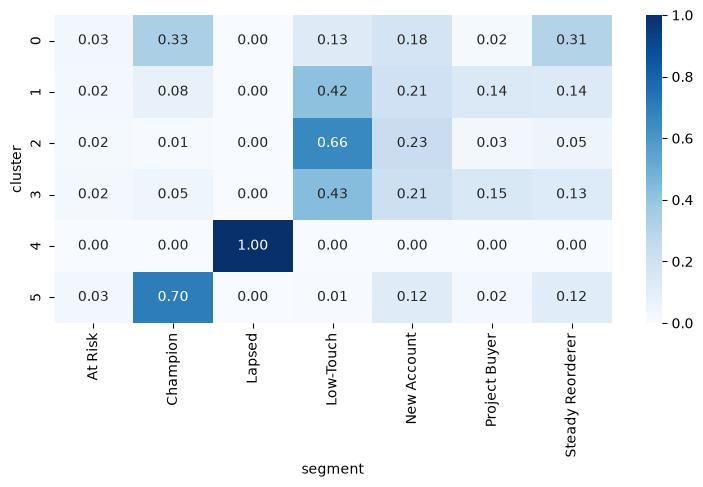

ARI: 0.208 | NMI: 0.314


In [20]:
K = 6  # set from the table above
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xtr)
train["cluster"], test["cluster"] = km.labels_, km.predict(Xte)

# Describe the clusters
display(train.groupby("cluster").agg(
    n=("account_id", "size"),
    purchase_rate=("ordered_next_30d", "mean"),
    orders_12m=("orders_12m", "median"),
    revenue_12m=("revenue_12m", "median"),
    days_since_last=("days_since_last_order", "median"),
    logins=("portal_logins_90d", "mean"),
    quotes=("quote_requests_90d", "mean"),
    rep_contacts=("rep_contacts_90d", "mean"),
    email_open=("email_open_rate_90d", "mean"),
    consumables=("consumables_revenue_share", "mean"),
).round(2))

# Cross-check vs rules: each row sums to 1 (where do a cluster's accounts land in the rule segments?)
ct = pd.crosstab(train.cluster, train.segment, normalize="index")
plt.figure(figsize=(9, 4)); sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues"); plt.show()
print("ARI:", round(adjusted_rand_score(train.segment, train.cluster), 3),
      "| NMI:", round(normalized_mutual_info_score(train.segment, train.cluster), 3))  # 0 = unrelated, 1 = identical

ARI & NMI score how similar two groupings of the same account are, 0 means unrelated, 1 means identical
ARI: Adjusted Rank Index -> Do 2 accounts that share a group in one scheme also share it in the other? random=0
NMI: Normalized Mutual Information -> How much knowing an account's cluster tells you about it's rule segment

0.3 is weak overlap, above 0.6 is strong. We have weak overlap here.

- cluster 0 -> a spread, but mostly champions & steady reorder & new accounts. So frequent & recent.
- cluster 1 -> low-touch, new accounts, a bit of everything
- cluster 2 -> big time low touch new accounts
- cluster 3 -> same as cluster 1, maybe we drop a cluster
- cluster 4 -> a 100% overlap with lapsed
- cluster 5 -> champions

,n,purchase_rate,orders_12m,revenue_12m,days_since_last,logins,quotes,rep_contacts,email_open,consumables
cluster,,,,,,,,,,
0,3627,0.62,11.0,14832.99,17.0,6.51,0.83,3.57,0.43,0.62
1,763,0.07,0.0,0.00,540.0,2.28,0.59,0.82,0.41,0.37
2,5210,0.23,3.0,3092.55,90.0,2.65,0.51,1.07,0.39,0.49


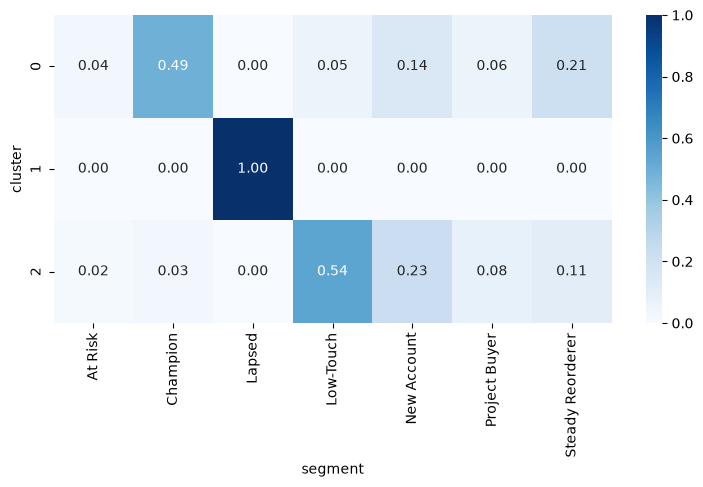

ARI: 0.296 | NMI: 0.386


In [21]:
K = 3  # set from the table above
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xtr)
train["cluster"], test["cluster"] = km.labels_, km.predict(Xte)

# Describe the clusters
display(train.groupby("cluster").agg(
    n=("account_id", "size"),
    purchase_rate=("ordered_next_30d", "mean"),
    orders_12m=("orders_12m", "median"),
    revenue_12m=("revenue_12m", "median"),
    days_since_last=("days_since_last_order", "median"),
    logins=("portal_logins_90d", "mean"),
    quotes=("quote_requests_90d", "mean"),
    rep_contacts=("rep_contacts_90d", "mean"),
    email_open=("email_open_rate_90d", "mean"),
    consumables=("consumables_revenue_share", "mean"),
).round(2))

# Cross-check vs rules: each row sums to 1 (where do a cluster's accounts land in the rule segments?)
ct = pd.crosstab(train.cluster, train.segment, normalize="index")
plt.figure(figsize=(9, 4)); sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues"); plt.show()
print("ARI:", round(adjusted_rand_score(train.segment, train.cluster), 3),
      "| NMI:", round(normalized_mutual_info_score(train.segment, train.cluster), 3))  # 0 = unrelated, 1 = identical

- cluster 0 -> champions
- cluster 1 -> 100% overlap with lapsed
- cluster 2 -> sready reorderers
- cluster 3 -> project buyers


### Quadrant Value vs. Customer-Initiated Engagement

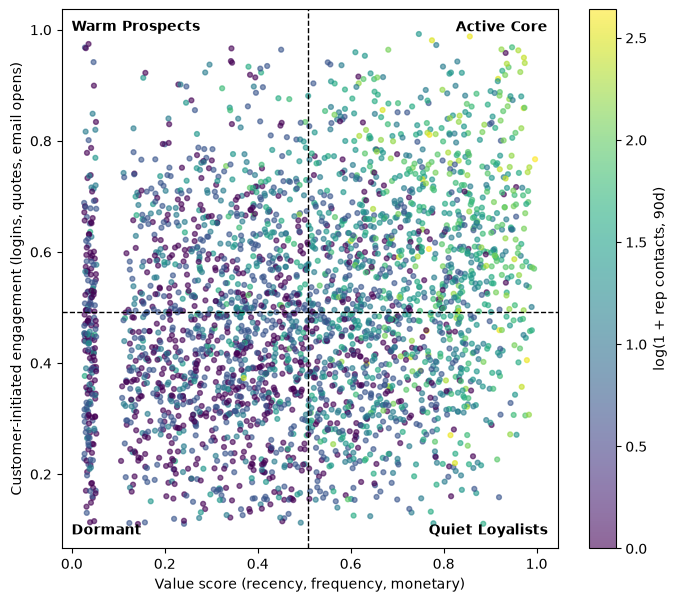

,n,purchase_rate,rep_contacts,quotes
quadrant,,,,
Active Core,2811,0.62,3.40,1.04
Dormant,2807,0.15,0.93,0.22
Quiet Loyalists,1989,0.47,2.19,0.17
Warm Prospects,1993,0.22,1.34,1.12


segment,At Risk,Champion,Lapsed,Low-Touch,New Account,Project Buyer,Steady Reorderer
quadrant,,,,,,,
Active Core,93,1230,0,142,433,292,621
Dormant,37,0,474,1590,571,73,62
Quiet Loyalists,71,695,0,209,257,144,613
Warm Prospects,25,0,289,1075,442,123,39


In [22]:
def add_axes(d, ref):
    d = d.copy()
    d["value_pct"] = np.mean([
        1 - pct_rank(ref.days_since_last_order, d.days_since_last_order),
        pct_rank(ref.orders_12m, d.orders_12m),
        pct_rank(ref.revenue_12m, d.revenue_12m),
    ], axis=0)
    d["engage_pct"] = np.mean([
        pct_rank(ref.portal_logins_90d, d.portal_logins_90d),
        pct_rank(ref.quote_requests_90d, d.quote_requests_90d),
        pct_rank(ref.email_open_rate_90d, d.email_open_rate_90d),
    ], axis=0)
    return d

train, test = add_axes(train, train), add_axes(test, train)
xc, yc = train.value_pct.median(), train.engage_pct.median()

def assign_quadrant(d):
    hi_v, hi_e = d.value_pct >= xc, d.engage_pct >= yc
    return np.select([hi_v & hi_e, hi_v & ~hi_e, ~hi_v & hi_e],
                     ["Active Core", "Quiet Loyalists", "Warm Prospects"], default="Dormant")

train["quadrant"], test["quadrant"] = assign_quadrant(train), assign_quadrant(test)

s = train.sample(3000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(s.value_pct, s.engage_pct, c=np.log1p(s.rep_contacts_90d), cmap="viridis", s=12, alpha=0.6)
ax.axvline(xc, color="k", ls="--", lw=1); ax.axhline(yc, color="k", ls="--", lw=1)
plt.colorbar(sc, label="log(1 + rep contacts, 90d)")
ax.set(xlabel="Value score (recency, frequency, monetary)", ylabel="Customer-initiated engagement (logins, quotes, email opens)")
for txt, xy, ha, va in [("Active Core", (0.98, 0.98), "right", "top"), ("Quiet Loyalists", (0.98, 0.02), "right", "bottom"),
                        ("Warm Prospects", (0.02, 0.98), "left", "top"), ("Dormant", (0.02, 0.02), "left", "bottom")]:
    ax.text(*xy, txt, transform=ax.transAxes, ha=ha, va=va, fontweight="bold")
plt.show()

display(train.groupby("quadrant").agg(
    n=("account_id", "size"),
    purchase_rate=("ordered_next_30d", "mean"),
    rep_contacts=("rep_contacts_90d", "mean"),
    quotes=("quote_requests_90d", "mean"),
).round(2))
pd.crosstab(train.quadrant, train.segment)

- Low-Touch are dormant and warm prospects, they're possibly engaged, but mostly unengaged, and definitley not purchasing - hit up the warm prospects first
- quiet loyalists get tons of rep contacts with very few quotes. Warm prospects get way more quotes per contact. may want to shift those contacts to the warm prospects.

## Machine Learning

### Features & Scoring Helpers

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

TARGET, VALUE_COL, TOP_FRAC = "ordered_next_30d", "next_30d_revenue", 0.09  # 9% ~ weekly call capacity

for d in (train, test):
    d["overdue_gt3"] = (d.overdue_ratio > 3).astype(int)

# 'segment' stays out of the ML features (it's built from these same numbers). It comes back as a Bayes group level
cat_features = ["industry_vertical", "region", "assigned_rep_id", "employee_band", "loyalty_tier"]
num_features = num_cols + ["overdue_ratio", "recent_share", "thin_flag", "no_orders_12m", "overdue_gt3"]
log_features = ["orders_12m", "orders_last_90d", "revenue_12m", "avg_order_value", "days_since_last_order",
                "lifetime_orders", "portal_logins_90d", "quote_requests_90d", "rep_contacts_90d"]
feature_cols = cat_features + num_features

y_tr = train[TARGET].to_numpy()
thin_tr = train.thin_flag.to_numpy() == 1
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # same folds for every model


def rank_metrics(y, s):
    y, s = np.asarray(y), np.asarray(s)
    top = np.argsort(-s)[: int(len(y) * TOP_FRAC)]
    prec = y[top].mean()
    return {"auc": roc_auc_score(y, s), "prec@top9%": prec, "lift@top9%": prec / y.mean()}


def prob_metrics(y, p, thin):
    y, p = np.asarray(y), np.asarray(p)
    return {"log_loss": log_loss(y, p), "brier": brier_score_loss(y, p),
            "logloss_thin": log_loss(y[thin], p[thin]), "logloss_other": log_loss(y[~thin], p[~thin])}


results = {}

### Baseline Models

In [24]:
# Reference: a model that predicts the base rate for everyone. Any real model must beat this log loss
base_p = np.full(len(y_tr), y_tr.mean())
results["Base rate only"] = {"auc": 0.5, **prob_metrics(y_tr, base_p, thin_tr)}

# The old way: rank by rule (these give a ranking, not probabilities, so no log loss)
results["Rule: most recent order"] = rank_metrics(y_tr, -train.days_since_last_order)
results["Rule: biggest accounts"] = rank_metrics(y_tr, train.revenue_12m)

### Logistic Regression

In [25]:
other_num = [c for c in num_features if c not in log_features]
pre_lr = ColumnTransformer([
    ("log", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), log_features),
    ("num", StandardScaler(), other_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])
lr = make_pipeline(pre_lr, LogisticRegressionCV(Cs=10, cv=5, scoring="neg_log_loss", max_iter=2000))

oof_lr = cross_val_predict(lr, train[feature_cols], y_tr, cv=cv, method="predict_proba")[:, 1]
results["Logistic regression"] = {**rank_metrics(y_tr, oof_lr), **prob_metrics(y_tr, oof_lr, thin_tr)}

pd.DataFrame(results).T.round(3)

,auc,log_loss,brier,logloss_thin,logloss_other,prec@top9%,lift@top9%
Base rate only,0.500,0.657,0.232,0.535,0.724,NaN,NaN
Rule: most recent order,0.732,NaN,NaN,NaN,NaN,0.686,1.872
Rule: biggest accounts,0.746,NaN,NaN,NaN,NaN,0.799,2.179
Logistic regression,0.802,0.509,0.168,0.387,0.576,0.907,2.475


- Base Rate is random, then we have 2 ranking methods: most recent order & biggest accounts, + a logistic regression.
- Logistic regression safely beats the rules on AUC, and adds a log loss to the mix.
- Log_loss & brier -> how good probabilities are, lower is better. Log loss is split out by thin accounts.
- Terrence mentioned 9% in his email as a rep's capacity for calls - if we picked the top 9% of selected accounts from this model, 91% of them would purchase. That's a 2.5x lift over picking at random!

### Tree Models

In [30]:
import optuna, joblib
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
try:
    from interpret.glassbox import ExplainableBoostingClassifier
    HAS_EBM = True
except ImportError:
    HAS_EBM = False

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_SCALE = 1.0  # set to 0.1 first as a smoke test, then back to 1.0 for the real run

# Each library wants categoricals differently, so three views of the same features
def as_category(d):
    d = d[feature_cols].copy()
    for c in cat_features:
        d[c] = pd.Categorical(d[c], categories=sorted(train[c].unique()))
    return d

X_views = {"oh": train[feature_cols],        # one-hot happens inside the pipeline (RF, ET, XGBoost)
           "cat": as_category(train),         # LightGBM native categoricals
           "str": train[feature_cols]}        # CatBoost / EBM handle strings natively

def prep_oh():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features)],
                             remainder="passthrough")

# ---- builders ----
def build_rf(p):   return make_pipeline(prep_oh(), RandomForestClassifier(**p, n_jobs=-1, random_state=42))
def build_et(p):   return make_pipeline(prep_oh(), ExtraTreesClassifier(**p, n_jobs=-1, random_state=42))
def build_xgb(p):  return make_pipeline(prep_oh(), XGBClassifier(**p, tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=42))
def build_lgbm(p): return LGBMClassifier(**p, subsample_freq=1, n_jobs=-1, random_state=42, verbose=-1)
def build_cat(p):  return CatBoostClassifier(**p, cat_features=cat_features, verbose=0, random_seed=42, thread_count=-1)
if HAS_EBM:
    def build_ebm(p): return ExplainableBoostingClassifier(**p, random_state=42, n_jobs=-1)

# ---- search spaces ----
def suggest_forest(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 200, 600, step=100),
                max_depth=t.suggest_int("max_depth", 4, 20),
                min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 60),
                max_features=t.suggest_float("max_features", 0.2, 0.8))

def suggest_xgb(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 200, 800, step=100),
                learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                max_depth=t.suggest_int("max_depth", 2, 6),
                min_child_weight=t.suggest_int("min_child_weight", 1, 30),
                subsample=t.suggest_float("subsample", 0.5, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
                reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True),
                reg_alpha=t.suggest_float("reg_alpha", 1e-3, 5, log=True))

def suggest_lgbm(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 200, 800, step=100),
                learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                num_leaves=t.suggest_int("num_leaves", 4, 64, log=True),
                min_child_samples=t.suggest_int("min_child_samples", 10, 100),
                subsample=t.suggest_float("subsample", 0.5, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
                reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True),
                reg_alpha=t.suggest_float("reg_alpha", 1e-3, 5, log=True))

def suggest_cat(t):
    return dict(iterations=t.suggest_int("iterations", 200, 800, step=100),
                learning_rate=t.suggest_float("learning_rate", 0.02, 0.2, log=True),
                depth=t.suggest_int("depth", 3, 8),
                l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1, 20, log=True))

def suggest_ebm(t):
    return dict(learning_rate=t.suggest_float("learning_rate", 0.005, 0.05, log=True),
                max_bins=t.suggest_categorical("max_bins", [64, 128, 256]),
                interactions=t.suggest_int("interactions", 0, 10),
                max_leaves=t.suggest_int("max_leaves", 2, 5),
                min_samples_leaf=t.suggest_int("min_samples_leaf", 2, 30))

models = {
    "Random forest": dict(view="oh",  build=build_rf,   suggest=suggest_forest, n_trials=30),
    "Extra trees":   dict(view="oh",  build=build_et,   suggest=suggest_forest, n_trials=30),
    "XGBoost":       dict(view="oh",  build=build_xgb,  suggest=suggest_xgb,    n_trials=50),
    "LightGBM":      dict(view="cat", build=build_lgbm, suggest=suggest_lgbm,   n_trials=50),
    # "CatBoost":      dict(view="str", build=build_cat,  suggest=suggest_cat,    n_trials=25),  # slowest
}
if HAS_EBM:
    models["EBM"] = dict(view="str", build=build_ebm, suggest=suggest_ebm, n_trials=20)           # also slow

- Runs 1.4s, just function definitions
- 

In [31]:
def tune(m):
    def objective(trial):
        p = cross_val_predict(m["build"](m["suggest"](trial)), X_views[m["view"]], y_tr,
                              cv=cv, method="predict_proba")[:, 1]
        trial.set_user_attr("oof", p.tolist())   # keep the out-of-fold predictions so we don't refit
        return log_loss(y_tr, p)
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=max(3, int(m["n_trials"] * N_SCALE)))
    return study

studies, oof = {}, {"Logistic regression": oof_lr}
for name, m in models.items():
    studies[name] = tune(m)
    oof[name] = np.array(studies[name].best_trial.user_attrs["oof"])
    results[name] = {**rank_metrics(y_tr, oof[name]), **prob_metrics(y_tr, oof[name], thin_tr)}
    print(f"{name}: best CV log loss {studies[name].best_value:.4f}")

joblib.dump({"oof": oof, "best_params": {k: s.best_params for k, s in studies.items()}}, "tuning_results.pkl")
pd.DataFrame(results).T.round(3)

Random forest: best CV log loss 0.5065
Extra trees: best CV log loss 0.5134
XGBoost: best CV log loss 0.5043
LightGBM: best CV log loss 0.5077
EBM: best CV log loss 0.5039


,auc,log_loss,brier,logloss_thin,logloss_other,prec@top9%,lift@top9%
Base rate only,0.500,0.657,0.232,0.535,0.724,NaN,NaN
Rule: most recent order,0.732,NaN,NaN,NaN,NaN,0.686,1.872
Rule: biggest accounts,0.746,NaN,NaN,NaN,NaN,0.799,2.179
Logistic regression,0.802,0.509,0.168,0.387,0.576,0.907,2.475
Random forest,0.804,0.506,0.167,0.390,0.571,0.902,2.460
EBM,0.805,0.504,0.166,0.388,0.567,0.905,2.469
Extra trees,0.798,0.513,0.170,0.395,0.578,0.896,2.444
XGBoost,0.806,0.504,0.166,0.387,0.569,0.899,2.453
LightGBM,0.802,0.508,0.168,0.390,0.572,0.904,2.466


In [ ]:
blend_names = ["XGBoost", "LightGBM"]  # edit after you see the table above
oof["Blend"] = np.mean([oof[n] for n in blend_names], axis=0)
results["Blend"] = {**rank_metrics(y_tr, oof["Blend"]), **prob_metrics(y_tr, oof["Blend"], thin_tr)}
pd.DataFrame(results).T.round(3)

## Model Validation

## Insights